In [1]:
#@title Imports and hyperparameters
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import os
import scipy
from scipy.stats import ttest_rel
from tqdm import tqdm

import datasets
from helpers import gather_seeds, simulate_models, reach_stats, dict_reach_stats, \
                    dict_to_csv, array_to_heatmap
from helpers_exploration import calc_exploration_metrics, \
                                region_counts_histogram, region_counts_histogram_df
from plots import plot_cov_hull, dataset_cmaps, plot_reference_lines, add_border_and_ticks
from metrics import calc_all_metric
#from wasserstein_distance import calc_all_wds

os.makedirs('csv', exist_ok=True)

dataset = 'tmaze'

# Hyperparameters
unmask_every = 3
sigma_s = sigma_r = 1
T_multiplier = 4
radius = 0.2 # radius within which endpoints have been "reached". NOTE: changed from 0.1!
dataset = 'triangle'

param_combos = []
for lambda_v in [1, 0.9, 0.8, 0.7]:
    for b_a in [0, 0.01, 0.02]:
        param_combos.append(
            {'sigma_r': sigma_r, 'lambda_v': lambda_v, 'b_a': b_a}
        )

In [2]:
endpoints = datasets.triangle_vertices_and_mus()[-1]
groups = 6

# Gather seeds
seeds = gather_seeds(f'{dataset}_dataset', f'unmask_every_{unmask_every}')
# other seeds have bad or weird replay
#seeds = [0, 1, 2, 5, 6, 7, 12, 15, 19]
#seeds = [0, 1, 2, 5, 6, 7, 12, 19]
#seeds = [0, 1, 2, 5, 6, 7, 8, 12, 19]
seeds = [0, 1, 2, 5, 6, 7, 8, 12, 17, 19]
#seeds = [0, 1, 2, 5, 6, 7, 8, 12, 17, 18, 19]
seeds = list(set(seeds)) # keep only unique values, since there are noleak seeds, too
print(seeds), print(len(seeds));

[0, 1, 2, 5, 6, 7, 8, 12, 17, 19]
10


In [3]:
# Simulate models
# replays is a dictionary of Tensors, awake_trajectories is one Tensor
replays, awake_trajectories = simulate_models(
    sigma_s=0.05, hidden_dim=40, T_multiplier=T_multiplier,
    param_combos=param_combos, seeds=seeds,
    model_dir='results', model_prefix=f'{dataset}_dataset__unmask_every_{unmask_every}',
    plaus=False
)

100%|███████████████████████████████████████████| 10/10 [00:13<00:00,  1.30s/it]


100%|███████████████████████████████████████████| 12/12 [00:54<00:00,  4.56s/it]


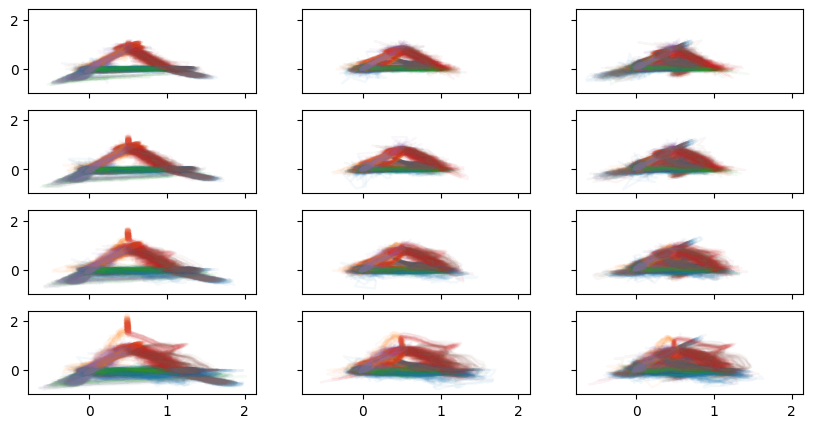

In [4]:
fig, axs = plt.subplots(nrows=4, ncols=3, figsize=(10,5), sharex=True, sharey=True)
axs = axs.flatten()
for i,p in enumerate(tqdm(param_combos)):
    x_hat = replays[str(p)]
    for j in range(len(seeds)):
        for g in range(groups):
            # x_hat has shape (T*T_multiplier, groups, len(seeds), N//groups, 2)
            axs[i].plot(x_hat[:,g,j,:,0], x_hat[:,g,j,:,1], c=f'C{g}', alpha=0.05)

100%|███████████████████████████████████████████| 12/12 [00:18<00:00,  1.53s/it]


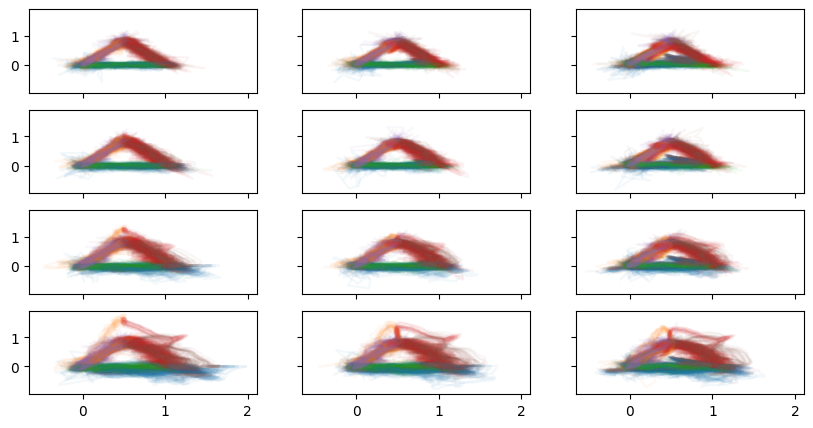

In [5]:
fig, axs = plt.subplots(nrows=4, ncols=3, figsize=(10,5), sharex=True, sharey=True)
axs = axs.flatten()
for i,p in enumerate(tqdm(param_combos)):
    x_hat = replays[str(p)]
    for j in range(len(seeds)):
        for g in range(groups):
            # x_hat has shape (T*T_multiplier, groups, len(seeds), N//groups, 2)
            axs[i].plot(x_hat[:100,g,j,:,0], x_hat[:100,g,j,:,1], c=f'C{g}', alpha=0.05)

In [17]:
every_region_count_value, region_count_avgs, \
every_distance, distance_avgs = calc_exploration_metrics(dataset, replays)

df_rcnt_avg = dict_to_csv(region_count_avgs, col_param="b_a",
                          path=f"csv/exploration_{dataset}_region_counts_avg.csv")
df_dist_avg = dict_to_csv(distance_avgs, col_param="b_a",
                          path=f"csv/exploration_{dataset}_distances_avg.csv")

In [7]:
print("Exploration p-values:")
p = {k: ttest_rel(every_region_count_value[str(param_combos[0])].flatten(),
                  v.flatten()).pvalue
     for (k,v) in every_region_count_value.items()}
p

Exploration p-values:


{"{'sigma_r': 1, 'lambda_v': 1, 'b_a': 0}": nan,
 "{'sigma_r': 1, 'lambda_v': 1, 'b_a': 0.01}": 4.474886316433805e-72,
 "{'sigma_r': 1, 'lambda_v': 1, 'b_a': 0.02}": 3.9171203459358673e-103,
 "{'sigma_r': 1, 'lambda_v': 0.9, 'b_a': 0}": 9.71514297496782e-05,
 "{'sigma_r': 1, 'lambda_v': 0.9, 'b_a': 0.01}": 1.9761512032790955e-69,
 "{'sigma_r': 1, 'lambda_v': 0.9, 'b_a': 0.02}": 1.1037457734663536e-97,
 "{'sigma_r': 1, 'lambda_v': 0.8, 'b_a': 0}": 2.2081622594976216e-06,
 "{'sigma_r': 1, 'lambda_v': 0.8, 'b_a': 0.01}": 2.4897490199881712e-68,
 "{'sigma_r': 1, 'lambda_v': 0.8, 'b_a': 0.02}": 4.4073330674681176e-99,
 "{'sigma_r': 1, 'lambda_v': 0.7, 'b_a': 0}": 7.478001698933914e-10,
 "{'sigma_r': 1, 'lambda_v': 0.7, 'b_a': 0.01}": 6.07472076336588e-70,
 "{'sigma_r': 1, 'lambda_v': 0.7, 'b_a': 0.02}": 1.4081729277813574e-102}

In [8]:
print("p-values above 0.05:")
{k: v for (k,v) in p.items() if v > 0.05}

p-values above 0.05:


{}

In [9]:
print("Distance-traveled p values:")
p = {k: ttest_rel(every_distance[str(param_combos[0])].flatten(), v.flatten()).pvalue
     for (k,v) in every_distance.items()}
p

Distance-traveled p values:


{"{'sigma_r': 1, 'lambda_v': 1, 'b_a': 0}": nan,
 "{'sigma_r': 1, 'lambda_v': 1, 'b_a': 0.01}": 4.765679056944591e-53,
 "{'sigma_r': 1, 'lambda_v': 1, 'b_a': 0.02}": 2.1963254972529417e-152,
 "{'sigma_r': 1, 'lambda_v': 0.9, 'b_a': 0}": 0.1306755964166026,
 "{'sigma_r': 1, 'lambda_v': 0.9, 'b_a': 0.01}": 5.9258042071258964e-37,
 "{'sigma_r': 1, 'lambda_v': 0.9, 'b_a': 0.02}": 6.88141624142927e-123,
 "{'sigma_r': 1, 'lambda_v': 0.8, 'b_a': 0}": 7.147136989947294e-19,
 "{'sigma_r': 1, 'lambda_v': 0.8, 'b_a': 0.01}": 6.061475938974922e-71,
 "{'sigma_r': 1, 'lambda_v': 0.8, 'b_a': 0.02}": 2.6692643118110182e-142,
 "{'sigma_r': 1, 'lambda_v': 0.7, 'b_a': 0}": 5.462523675263006e-131,
 "{'sigma_r': 1, 'lambda_v': 0.7, 'b_a': 0.01}": 7.576164962895182e-147,
 "{'sigma_r': 1, 'lambda_v': 0.7, 'b_a': 0.02}": 3.968857846990281e-189}

In [10]:
print("p-values above 0.05:")
{k: v for (k,v) in p.items() if v > 0.05}

p-values above 0.05:


{"{'sigma_r': 1, 'lambda_v': 0.9, 'b_a': 0}": 0.1306755964166026}

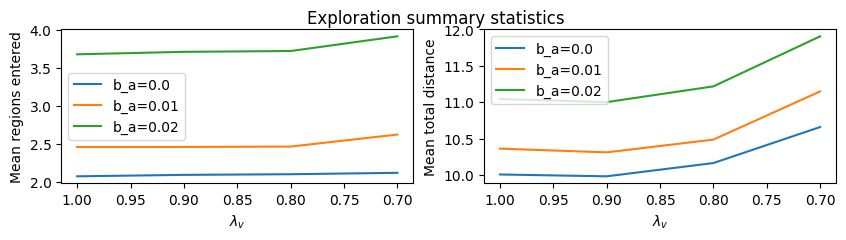

In [11]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10,2))
for i, b_a in enumerate([0.0, 0.01, 0.02]):
    x = df_rcnt_avg['lambda_v']
    label = f'{b_a=}'
    axs[0].plot(x, df_rcnt_avg[label], label=label)
    axs[1].plot(x, df_dist_avg[f'{b_a=}'], label=label)
for ax in axs:
    ax.legend()
    ax.xaxis.set_inverted(True)
    ax.set(xlabel='$\lambda_v$')
axs[0].set(ylabel='Mean regions entered')
axs[1].set(ylabel='Mean total distance')
fig.suptitle('Exploration summary statistics')
fig.show()

In [12]:
# flatten replays: combine the len(seeds) and num samples dimensions together.
replays = {k: v.flatten(start_dim=2, end_dim=3) for (k,v) in replays.items()}
# calculate reach time statistics
reach_times, rt_meds, rt_avgs, rt_stds, failure_rates = \
    dict_reach_stats(replays, endpoints, radius)
awake_rts, awake_rt_med, awake_rt_avg, awake_rt_std, _ = \
    reach_stats(awake_trajectories, endpoints, radius)
# reshape medians and avgs for plotting
delta_arrays = {
    'median':  (np.array(list(rt_meds.values())).reshape(4,3) / awake_rt_med - 1) * 100,
    'average': (np.array(list(rt_avgs.values())).reshape(4,3) / awake_rt_avg - 1) * 100
}

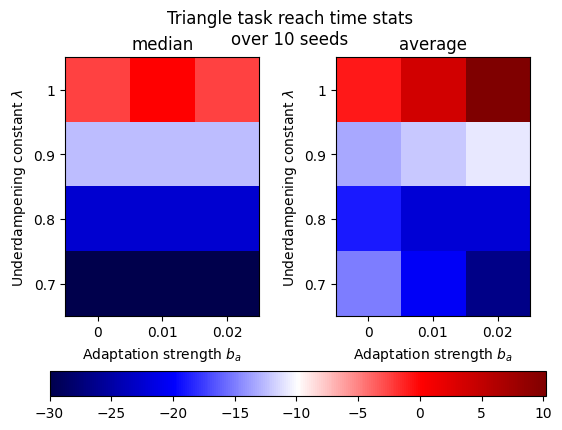

In [13]:
cmap = plt.cm.seismic #c = 'seismic'
fig, axs = plt.subplots(nrows=1, ncols=len(delta_arrays))
vmin = min([a.min() for a in delta_arrays.values()])
vmax = max([a.max() for a in delta_arrays.values()])
for i,(k,v) in enumerate(delta_arrays.items()):
    im = axs[i].imshow(v, cmap=cmap, vmin=vmin, vmax=vmax)
    axs[i].set(title=k,
               xlabel='Adaptation strength $b_a$',
               ylabel='Underdampening constant $\lambda$',
               xticks=[0,1,2], xticklabels=[0,0.01,0.02],
               yticks=[0,1,2,3], yticklabels=[1,0.9,0.8,0.7])
fig.colorbar(im, ax=axs.ravel().tolist(), location='bottom')
fig.suptitle(f'Triangle task reach time stats\nover {len(seeds)} seeds');

In [14]:
# save results
array_to_heatmap(delta_arrays['median'],  f'csv/med_rt_heatmap_{dataset}.txt')
array_to_heatmap(delta_arrays['average'], f'csv/avg_rt_heatmap_{dataset}.txt');

Make sure to add newlines before plotting in TikZ
Make sure to add newlines before plotting in TikZ


In [15]:
wds = calc_all_metric(replays, awake_trajectories, 'wd')
wds = dict_to_csv(wds, col_param='b_a', path=f'csv/wd_{dataset}.csv');

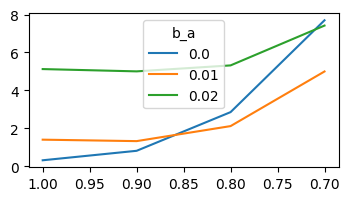

In [16]:
plt.figure(figsize=(4,2))
for b_a in [0.0, 0.01, 0.02]:
    plt.plot(wds['lambda_v'], wds[f'b_a={b_a}'], label=b_a)
plt.legend(title='b_a')
plt.gca().xaxis.set_inverted(True)